# Milestone 2 : Mesurer la situation actuelle

## Section 0 : Notre objectif et nos données

Avant d'optimiser, nous mesurons. On ne peut pas améliorer ce qu'on ne peut pas
mesurer. Ce notebook décrit la situation actuelle, construit notre estimateur de
coût, et fixe la **baseline** que notre algorithme devra battre au milestone 3.

Nous travaillons avec **trois principes** :

1. **Un camion = une livraison = un jour** (remarque du professeur). Notre unité
   de base est l'**envoi** : un fournisseur livre une usine un jour donné
   (`supplier_id` x `plant` x `date`). Capacité, nombre de camions et coût se
   calculent toujours **par envoi**, jamais sur un total de semaine.
2. **Nous ne chiffrons et n'optimisons que ce que nous connaissons (H15).** Notre
   périmètre, ce sont les lignes au statut `optimise`. Toutes nos comparaisons se
   font sur ce périmètre. Les lignes `non optimise : info manquante` sont traitées
   à part (section 5.2).
3. **Pour l'inconnu, nous prenons le pire cas (H16) : chaque ligne incomplète
   occupe un camion plein, seule.** Ces lignes sont chiffrées de la même façon
   avant et après optimisation : elles ne changent pas l'économie calculée. C'est
   volontairement pessimiste : la réalité ne peut être que meilleure.

**Nos hypothèses :**

- **H13 (validée)** : un envoi à plusieurs camions est facturé camions pleins au
  tarif `>4000` plus le dernier au poids restant (lecture fidèle de la grille pour
  un envoi scindé).
- **H15** : nous ne chiffrons et n'optimisons que les lignes `optimise` ; le reste
  est traité à part et n'entre jamais dans nos économies.
- **H16 (pire cas)** : chaque ligne inconnue occupe un camion plein, seule.
  Volontairement pessimiste : la réalité ne peut être que meilleure.

Rappels des règles : capacité **24 500 kg** ou **110,4 m³** (R2) ; un camion = un
seul couple (R3) ; avance de **7 jours** au plus, jamais de retard (R1) ; tarif
`>4000` jusqu'à 24,5 t (H12) ; horizon utile du **09/11 au 18/12/2026**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Nos parametres, au meme endroit.
CHEMIN_PLANNING = "../data/processed/planning_propre.csv"
CHEMIN_GRILLE = "../data/processed/grille_prix.csv"
DOSSIER_SORTIE = "../data/processed/"
CAP_POIDS = 24500.0    # kg par camion (R2)
CAP_VOLUME = 110.4     # m3 par camion (R2)
TRANCHES_KG = [50, 100, 200, 300, 400, 500, 750, 1000, 1500, 2000, 2500, 3000, 3500, 4000]  # au-dela : ">4000"
TRANCHES_KM = [30, 50, 75, 100, 125, 150, 175, 200, 250, 300, 400, 500, 650]                # au-dela : ">650"
print("Parametres charges.")

Parametres charges.


Nous chargeons nos données issues du pipeline du milestone 1. Si un fichier
manque, nous le disons clairement.

In [2]:
import os

def charger(chemin_planning, chemin_grille):
    """Charge le planning propre et la grille de prix ; message clair si un fichier manque."""
    for f in (chemin_planning, chemin_grille):
        if not os.path.exists(f):
            raise FileNotFoundError("Fichier manquant : " + f + ". Lancer d'abord le notebook milestone1.")
    planning = pd.read_csv(chemin_planning, parse_dates=["date", "semaine"])
    grille = pd.read_csv(chemin_grille, index_col=0)
    grille.columns = grille.columns.astype(str)
    grille.index = grille.index.astype(str)
    return planning, grille

planning, grille_prix = charger(CHEMIN_PLANNING, CHEMIN_GRILLE)
NB_SEMAINES = planning["semaine"].nunique()
print("Planning :", planning.shape[0], "lignes,", planning.shape[1], "colonnes")
print("Grille   :", grille_prix.shape[0], "x", grille_prix.shape[1])
print("Semaines de l'horizon :", NB_SEMAINES)

Planning : 4390 lignes, 19 colonnes
Grille   : 14 x 15
Semaines de l'horizon : 6


Notre périmètre : combien de lignes, de poids et de couples sont `optimise`,
et combien sont mis de côté.

,lignes,poids_tonnes,couples
optimise,4252,1614.9,171
non optimise,138,0.5,30


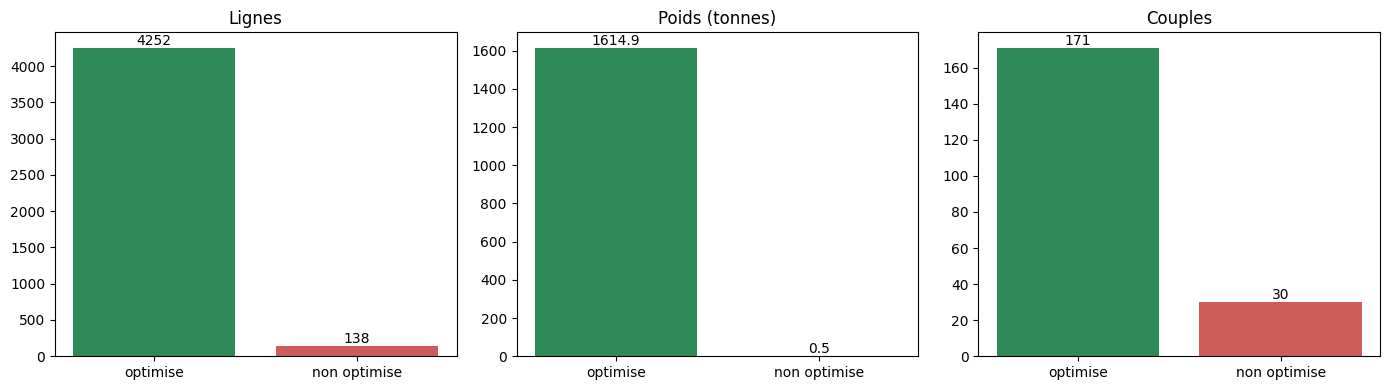

In [3]:
# Separation du perimetre optimise et des lignes non optimisees.
optimise = planning[planning["statut"] == "optimise"].copy()
non_optimise = planning[planning["statut"] != "optimise"].copy()

perimetre = pd.DataFrame({
    "lignes": [len(optimise), len(non_optimise)],
    "poids_tonnes": [round(optimise["weight"].sum() / 1000, 1), round(non_optimise["weight"].sum() / 1000, 1)],
    "couples": [optimise.groupby(["supplier_id", "plant"]).ngroups,
                non_optimise.groupby(["supplier_id", "plant"]).ngroups],
}, index=["optimise", "non optimise"])
display(perimetre)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, titre in zip(axes, ["lignes", "poids_tonnes", "couples"],
                          ["Lignes", "Poids (tonnes)", "Couples"]):
    barres = ax.bar(perimetre.index, perimetre[col], color=["seagreen", "indianred"])
    ax.set_title(titre)
    for b, v in zip(barres, perimetre[col]):
        ax.text(b.get_x() + b.get_width() / 2, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Notre constat :** sur **4 390** besoins, **4 252** (96,9 %) sont `optimise`
et **138** sont mis de côté faute de poids, de volume ou de distance. Leur poids
est inconnu (mis à 0 par H4) : le graphique n'en montre que la partie connue ;
nous les chiffrons au pire cas en section 5.2. Toute la suite porte sur le
périmètre optimisé ; les lignes inconnues sont traitées à part.

## Section 1 : Notre situation actuelle complète

Notre situation actuelle a deux parties : les envois que nous connaissons et
pouvons optimiser (1.a), et les lignes dont il manque une information, que nous
chiffrons au pire cas (1.b). Le total des deux donne notre situation complète (1.c).

### 1.a Les envois de notre périmètre optimisé

Nous construisons notre table de base, un **envoi** par ligne : un fournisseur,
une usine, un jour. Pour chaque envoi, nous comptons les camions et le
remplissage. La règle des camions :
`nb_camions = max(1, arrondi sup(poids / 24 500), arrondi sup(volume / 110,4))`.
Le remplissage est le poids (ou le volume) rapporté à la capacité totale des
camions de l'envoi.

In [4]:
def nb_camions(poids, volume):
    """Nombre de camions d'un envoi : la premiere limite atteinte, poids ou volume (R2)."""
    return max(1, int(np.ceil(poids / CAP_POIDS)), int(np.ceil(volume / CAP_VOLUME)))

# Un envoi = supplier_id x plant x date (un camion = une livraison = un jour).
cle = ["supplier_id", "plant", "date"]
envois = optimise.groupby(cle).agg(
    semaine=("semaine", "first"), jour=("jour", "first"),
    nb_lignes=("weight", "size"), nb_pieces=("schedule_quantity", "sum"),
    poids=("weight", "sum"), volume=("volume", "sum"),
    distance=("distance", "first"), ligne_grille=("ligne_grille", "first")).reset_index()
envois["nb_camions"] = [nb_camions(p, v) for p, v in zip(envois["poids"], envois["volume"])]
envois["remplissage_poids_%"] = envois["poids"] / (envois["nb_camions"] * CAP_POIDS) * 100
envois["remplissage_volume_%"] = envois["volume"] / (envois["nb_camions"] * CAP_VOLUME) * 100
envois.head()

,supplier_id,plant,date,semaine,jour,nb_lignes,nb_pieces,poids,volume,distance,ligne_grille,nb_camions,remplissage_poids_%,remplissage_volume_%
0,SUP_00001,PLT_004,2026-11-26,2026-11-23,jeudi,3,168.0,520.2,2.97360,47.0,50.0,1,2.123265,2.693478
1,SUP_00001,PLT_004,2026-12-16,2026-12-14,mercredi,3,303.0,584.2,2.97360,47.0,50.0,1,2.384490,2.693478
2,SUP_00003,PLT_001,2026-11-10,2026-11-09,mardi,1,25.0,90.6,0.41160,83.0,100.0,1,0.369796,0.372826
3,SUP_00003,PLT_001,2026-11-13,2026-11-09,vendredi,1,100.0,115.5,0.01764,83.0,100.0,1,0.471429,0.015978
4,SUP_00003,PLT_001,2026-11-24,2026-11-23,mardi,1,25.0,90.6,0.41160,83.0,100.0,1,0.369796,0.372826


In [5]:
nb_envois = len(envois)
nb_couples = envois.groupby(["supplier_id", "plant"]).ngroups
nb_camions_total = int(envois["nb_camions"].sum())
print("Envois  :", nb_envois)
print("Couples :", nb_couples)
print("Camions :", nb_camions_total)
print("Controle camions >= envois :", nb_camions_total >= nb_envois,
      "(", nb_camions_total, ">=", nb_envois, ")")

Envois  : 1599
Couples : 171
Camions : 1604
Controle camions >= envois : True ( 1604 >= 1599 )


**Notre constat :** notre périmètre compte **1 599 envois** pour **171
couples**, soit **1 604 camions**. Le contrôle passe : il y a au moins un camion
par envoi. En moyenne, un envoi tient dans un seul camion ; les exceptions sont
rares (section 3).

### 1.b Les lignes que nous ne connaissons pas (H16)

Pour chaque ligne au statut `non optimise : info manquante`, nous retenons le
**pire cas** : la ligne occupe **un camion plein, seule**, à sa date d'origine.
Si sa distance est inconnue, nous prenons la ligne de grille de la **distance
maximale** de nos fournisseurs. Une ligne par ligne inconnue, un camion chacune.

In [6]:
# Chaque ligne inconnue = un camion plein, seule, a sa date d'origine (H16).
# Regle de distance identique a ligne_depuis_distance (definie en section 4).
distance_max = planning["distance"].max()
ligne_distance_max = float(next((t for t in TRANCHES_KM if distance_max <= t), 650))

def raison_manque(r):
    """Pourquoi la ligne est inconnue : poids, volume et/ou distance manquants."""
    motifs = []
    if r["poids_manquant"]:
        motifs.append("poids manquant")
    if r["volume_manquant"]:
        motifs.append("volume manquant")
    if r["sans_distance"]:
        motifs.append("distance manquante")
    return " + ".join(motifs)

lignes_inconnues = non_optimise.copy()
lignes_inconnues["raison"] = lignes_inconnues.apply(raison_manque, axis=1)
lignes_inconnues["ligne_grille"] = np.where(lignes_inconnues["sans_distance"],
                                            ligne_distance_max, lignes_inconnues["ligne_grille"])
lignes_inconnues["nb_camions"] = 1
lignes_inconnues = lignes_inconnues[["supplier_id", "plant", "date", "raison",
                                     "ligne_grille", "nb_camions"]].reset_index(drop=True)
print("Lignes inconnues (un camion plein chacune) :", len(lignes_inconnues))
display(lignes_inconnues.head(10))

Lignes inconnues (un camion plein chacune) : 138


,supplier_id,plant,date,raison,ligne_grille,nb_camions
0,SUP_00107,PLT_002,2026-11-09,poids manquant + volume manquant,30.0,1
1,SUP_00109,PLT_002,2026-11-09,poids manquant + volume manquant,30.0,1
2,SUP_00117,PLT_002,2026-11-09,poids manquant + volume manquant,30.0,1
3,SUP_00133,PLT_002,2026-11-09,poids manquant + volume manquant,75.0,1
4,SUP_00112,PLT_004,2026-11-10,poids manquant + volume manquant,75.0,1
5,SUP_00117,PLT_002,2026-11-10,poids manquant + volume manquant,30.0,1
6,SUP_00129,PLT_003,2026-11-10,poids manquant + volume manquant,100.0,1
7,SUP_00153,PLT_004,2026-11-10,poids manquant + volume manquant,100.0,1
8,SUP_00153,PLT_004,2026-11-10,poids manquant + volume manquant,100.0,1
9,SUP_00153,PLT_004,2026-11-10,poids manquant + volume manquant,100.0,1


### 1.c Le total de notre situation actuelle

Nous additionnons les deux parties : les camions du périmètre optimisé et les
camions des lignes inconnues (un par ligne, H16). Pour information, nous comptons
aussi les envois réels (toutes les lignes groupées par fournisseur x usine x jour)
et les envois mixtes, qui mélangent lignes connues et lignes inconnues.

,situation actuelle complete,nombre
0,Envois du perimetre optimise,1599
1,Camions du perimetre optimise,1604
2,"Camions des lignes inconnues (H16, un par ligne)",138
3,Camions de la situation complete,1742
4,Pour info : envois reels (lignes groupees par ...,1665
5,Pour info : envois mixtes (connues + inconnues),59


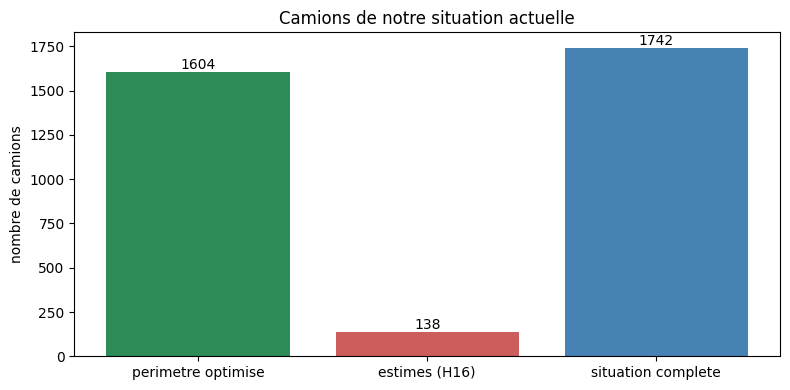

In [7]:
# Envois reels : toutes les lignes groupees par fournisseur x usine x jour.
tous = planning.copy()
tous["connue"] = tous["statut"] == "optimise"
agg_reels = tous.groupby(cle)["connue"].agg(lignes="size", connues="sum")
envois_reels = len(agg_reels)
envois_mixtes = int(((agg_reels["connues"] > 0) & (agg_reels["connues"] < agg_reels["lignes"])).sum())

camions_inconnues = len(lignes_inconnues)
camions_complet = nb_camions_total + camions_inconnues

recap = pd.DataFrame([
    ("Envois du perimetre optimise", nb_envois),
    ("Camions du perimetre optimise", nb_camions_total),
    ("Camions des lignes inconnues (H16, un par ligne)", camions_inconnues),
    ("Camions de la situation complete", camions_complet),
    ("Pour info : envois reels (lignes groupees par fournisseur x usine x jour)", envois_reels),
    ("Pour info : envois mixtes (connues + inconnues)", envois_mixtes),
], columns=["situation actuelle complete", "nombre"])
display(recap)

fig, ax = plt.subplots(figsize=(8, 4))
vals = [nb_camions_total, camions_inconnues, camions_complet]
labels = ["perimetre optimise", "estimes (H16)", "situation complete"]
barres = ax.bar(labels, vals, color=["seagreen", "indianred", "steelblue"])
ax.set_title("Camions de notre situation actuelle")
ax.set_ylabel("nombre de camions")
for b, v in zip(barres, vals):
    ax.text(b.get_x() + b.get_width() / 2, v, str(int(v)), ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Notre constat :** notre situation complète compte **1 742 camions** : **1 604**
sur notre périmètre optimisé et **138** pour les lignes inconnues (un camion plein
chacune, H16). Les lignes se regroupent en **1 665 envois réels**, dont **59
mixtes**. Un envoi mixte contient à la fois des lignes connues et des lignes
inconnues : nous le comptons séparément, un camion pour sa partie connue et un
camion par ligne inconnue qu'il contient. C'est voulu, un choix pessimiste qui
joue contre nous.

## Section 2 : Comment nous livrons aujourd'hui

Nous regardons comment les envois se répartissent : par couple, par usine, par
semaine et par jour. Cela montre d'où vient le gaspillage et prépare le lissage
du milestone 3.

**Par couple** : combien d'envois par semaine, en moyenne, pour un couple
qui livre ?

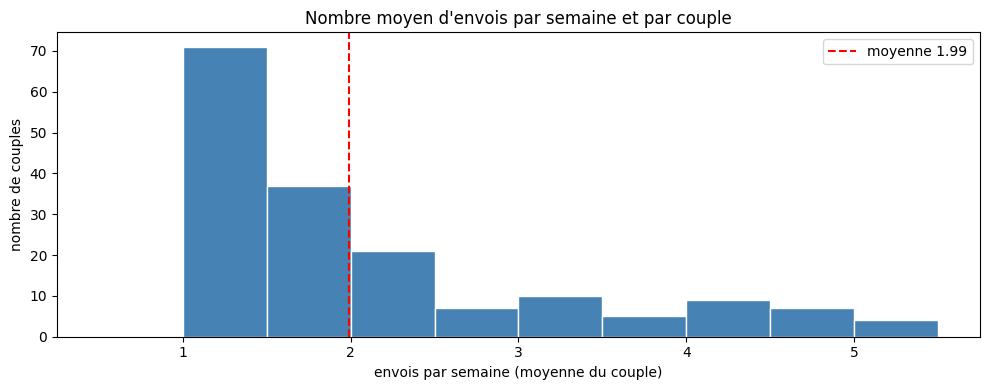

Moyenne : 1.99 | mediane : 1.5 | max : 5.0


In [8]:
envois_couple_sem = envois.groupby(["supplier_id", "plant", "semaine"]).size().reset_index(name="n")
moyenne_couple = envois_couple_sem.groupby(["supplier_id", "plant"])["n"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(moyenne_couple, bins=np.arange(0.5, moyenne_couple.max() + 1, 0.5), color="steelblue", edgecolor="white")
ax.axvline(moyenne_couple.mean(), color="red", linestyle="--", label="moyenne " + str(round(moyenne_couple.mean(), 2)))
ax.set_title("Nombre moyen d'envois par semaine et par couple")
ax.set_xlabel("envois par semaine (moyenne du couple)"); ax.set_ylabel("nombre de couples")
ax.legend()
plt.tight_layout()
plt.show()
print("Moyenne :", round(moyenne_couple.mean(), 2), "| mediane :", round(moyenne_couple.median(), 2),
      "| max :", round(moyenne_couple.max(), 2))

**Notre constat :** un couple livre en moyenne **2 fois par semaine** (jusqu'à
5). Chaque livraison part presque vide : c'est exactement ce que le regroupement
va corriger.

**Par usine** : nombre d'envois et poids total.

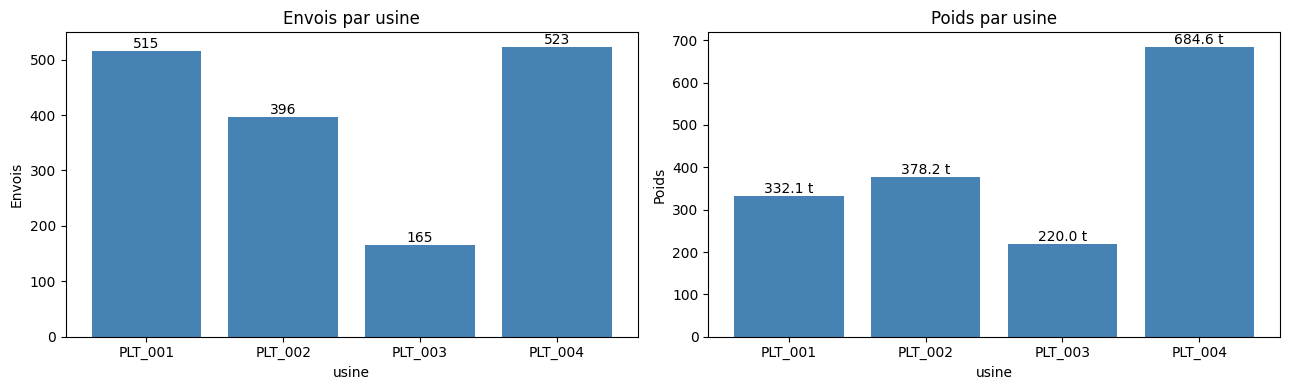

In [9]:
par_usine = envois.groupby("plant").agg(envois=("poids", "size"),
                                         poids_tonnes=("poids", lambda s: s.sum() / 1000)).reset_index()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, titre, unite in [(ax1, "envois", "Envois par usine", ""),
                              (ax2, "poids_tonnes", "Poids par usine", " t")]:
    barres = ax.bar(par_usine["plant"], par_usine[col], color="steelblue")
    ax.set_title(titre); ax.set_xlabel("usine"); ax.set_ylabel(titre.split(" ")[0])
    for b, v in zip(barres, par_usine[col]):
        ax.text(b.get_x() + b.get_width() / 2, v, str(round(v, 1)) + unite, ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Notre constat :** PLT_004 et PLT_001 reçoivent le plus d'envois (523 et
515) ; PLT_004 concentre aussi le plus de poids (**685 t**). PLT_003 est la plus
petite (165 envois). Le potentiel de regroupement est surtout sur les grosses
usines.

**Par semaine** : nombre d'envois et poids total.

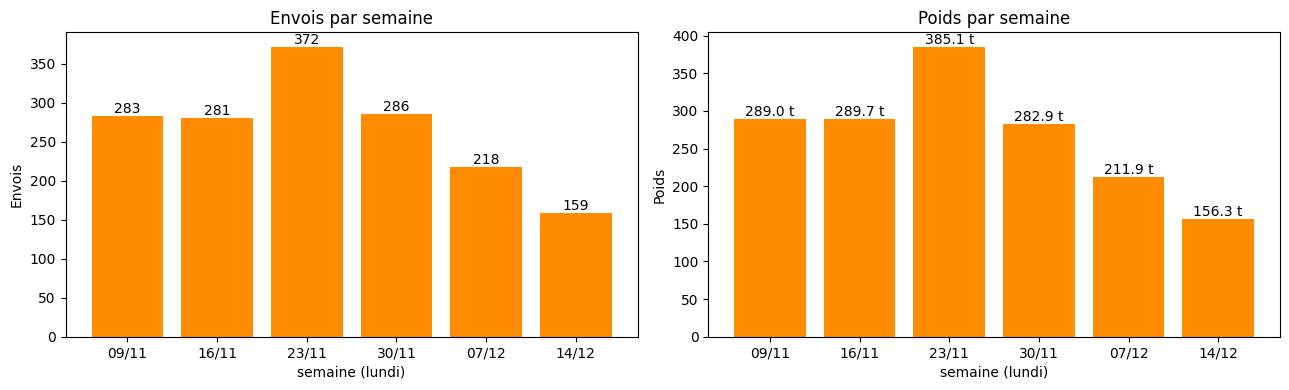

In [10]:
par_semaine = envois.groupby(envois["semaine"].dt.date).agg(
    envois=("poids", "size"), poids_tonnes=("poids", lambda s: s.sum() / 1000)).reset_index()
etiquettes = [d.strftime("%d/%m") for d in par_semaine["semaine"]]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, titre, unite in [(ax1, "envois", "Envois par semaine", ""),
                              (ax2, "poids_tonnes", "Poids par semaine", " t")]:
    barres = ax.bar(etiquettes, par_semaine[col], color="darkorange")
    ax.set_title(titre); ax.set_xlabel("semaine (lundi)"); ax.set_ylabel(titre.split(" ")[0])
    for b, v in zip(barres, par_semaine[col]):
        ax.text(b.get_x() + b.get_width() / 2, v, str(round(v, 0 if col == "envois" else 1)) + unite,
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Notre constat :** la charge est assez régulière (environ **280 envois** par
semaine), avec un pic le **23/11** (372 envois) et une fin d'horizon plus calme le
**14/12** (159). La semaine du **14/12**, PLT_002 n'a aucun envoi de notre
périmètre. Les moyennes par semaine sont donc fiables.

**Par jour** : les envois du lundi au vendredi.

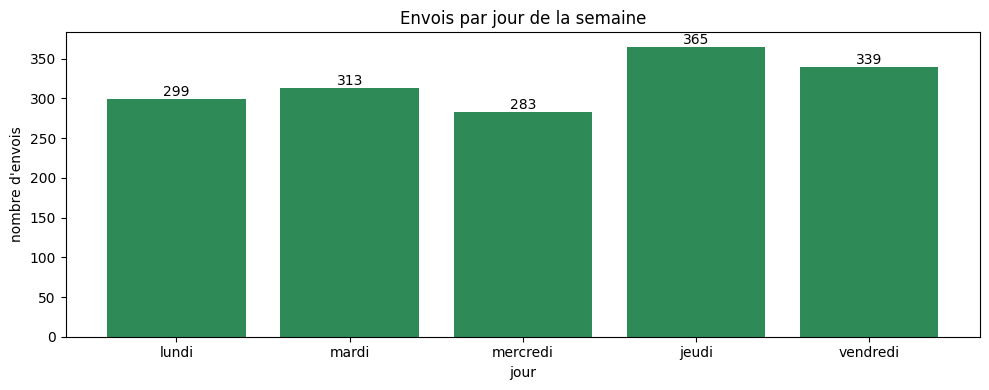

In [11]:
ordre_jours = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
par_jour = envois.groupby("jour").size().reindex(ordre_jours).dropna()
fig, ax = plt.subplots(figsize=(10, 4))
barres = ax.bar(par_jour.index, par_jour.values, color="seagreen")
ax.set_title("Envois par jour de la semaine")
ax.set_xlabel("jour"); ax.set_ylabel("nombre d'envois")
for b, v in zip(barres, par_jour.values):
    ax.text(b.get_x() + b.get_width() / 2, v, str(int(v)), ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Notre constat :** les livraisons tombent du **lundi au vendredi**, aucune
livraison le week-end, avec un pic le **jeudi** (365). Pour le milestone 3, nos
jours de lissage seront donc choisis parmi les cinq jours ouvrés.

## Section 3 : Le remplissage de nos camions

Nous regardons à quel point nos camions sont vides. C'est le cœur du problème :
beaucoup de camions presque vides coûtent cher pour rien.

**Distribution** du poids et du volume par envoi (échelle log, médiane
indiquée).

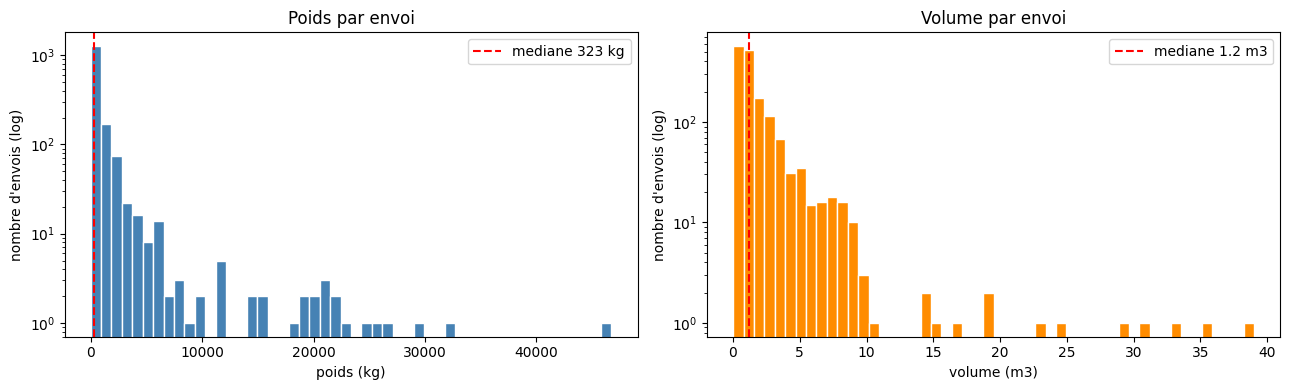

Capacite d'un camion : 24500 kg / 110.4 m3


In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.hist(envois["poids"], bins=50, color="steelblue", edgecolor="white")
ax1.axvline(envois["poids"].median(), color="red", linestyle="--",
            label="mediane " + str(round(envois["poids"].median())) + " kg")
ax1.set_yscale("log"); ax1.set_title("Poids par envoi")
ax1.set_xlabel("poids (kg)"); ax1.set_ylabel("nombre d'envois (log)"); ax1.legend()
ax2.hist(envois["volume"], bins=50, color="darkorange", edgecolor="white")
ax2.axvline(envois["volume"].median(), color="red", linestyle="--",
            label="mediane " + str(round(envois["volume"].median(), 2)) + " m3")
ax2.set_yscale("log"); ax2.set_title("Volume par envoi")
ax2.set_xlabel("volume (m3)"); ax2.set_ylabel("nombre d'envois (log)"); ax2.legend()
plt.tight_layout()
plt.show()
print("Capacite d'un camion :", int(CAP_POIDS), "kg /", CAP_VOLUME, "m3")

**Notre constat :** l'envoi médian pèse **323 kg** pour **1,2 m³**, loin des
**24 500 kg** et **110,4 m³** d'un camion. La très grande majorité des envois sont
minuscules devant la capacité.

**Classes de remplissage** (en poids) et part des envois sous 10 %.

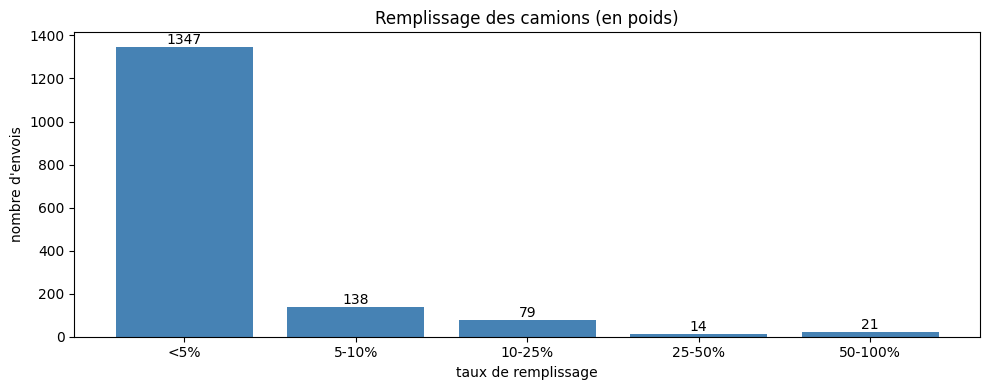

Part des envois remplis a moins de 10 % : 92.9 %


In [13]:
bornes = [0, 5, 10, 25, 50, 100.0001]
libelles = ["<5%", "5-10%", "10-25%", "25-50%", "50-100%"]
classes = pd.cut(envois["remplissage_poids_%"], bins=bornes, labels=libelles, include_lowest=True)
compte = classes.value_counts().reindex(libelles)
fig, ax = plt.subplots(figsize=(10, 4))
barres = ax.bar(compte.index, compte.values, color="steelblue")
ax.set_title("Remplissage des camions (en poids)")
ax.set_xlabel("taux de remplissage"); ax.set_ylabel("nombre d'envois")
for b, v in zip(barres, compte.values):
    ax.text(b.get_x() + b.get_width() / 2, v, str(int(v)), ha="center", va="bottom")
plt.tight_layout()
plt.show()
part_sous_10 = (envois["remplissage_poids_%"] < 10).mean() * 100
print("Part des envois remplis a moins de 10 % :", round(part_sous_10, 1), "%")

**Notre constat :** **92,9 %** des envois remplissent le camion à **moins de
10 %** en poids. Nous transportons surtout du vide. C'est là que se trouve
l'économie.

**Quelle limite est la plus serrée** : le poids ou le volume ?

In [14]:
actifs = envois[envois["nb_camions"] > 0]
rp = actifs["remplissage_poids_%"]
rv = actifs["remplissage_volume_%"]
print("Remplissage poids  : mediane", round(rp.median(), 2), "% | moyenne", round(rp.mean(), 2), "%")
print("Remplissage volume : mediane", round(rv.median(), 2), "% | moyenne", round(rv.mean(), 2), "%")
part_poids = (actifs["remplissage_poids_%"] >= actifs["remplissage_volume_%"]).mean() * 100
print("Le poids est la limite la plus serree pour", round(part_poids), "% des envois.")

Remplissage poids  : mediane 1.32 % | moyenne 3.92 %
Remplissage volume : mediane 1.09 % | moyenne 1.57 %
Le poids est la limite la plus serree pour 69 % des envois.


**Notre constat :** pour **69 %** de nos envois, le camion se remplit plus vite
en poids qu'en volume : quand nous regrouperons les envois, c'est surtout le poids
(**24,5 t**) qui limitera le chargement.

**Combien d'envois** demandent plus d'un camion ?

In [15]:
multi = envois[envois["nb_camions"] > 1]
print("Envois demandant plus d'un camion :", len(multi), "sur", len(envois))
display(multi[["supplier_id", "plant", "date", "poids", "volume", "nb_camions"]])

Envois demandant plus d'un camion : 5 sur 1599


,supplier_id,plant,date,poids,volume,nb_camions
286,SUP_00037,PLT_002,2026-11-27,25722.70,39.00800,2
418,SUP_00046,PLT_004,2026-11-11,46733.64,6.45408,2
420,SUP_00046,PLT_004,2026-11-25,26535.24,7.37568,2
421,SUP_00046,PLT_004,2026-12-02,32306.82,9.31872,2
645,SUP_00074,PLT_003,2026-12-15,29351.45,2.52000,2


**Notre constat :** seuls **5 envois** dépassent un camion (ils sont lourds).
Pour tous les autres, un envoi tient dans un camion : le problème n'est pas la
capacité, c'est le nombre de camions presque vides.

## Section 4 : Notre estimateur de coût

Nous expliquons ici, pas à pas, comment nous passons d'un envoi à un prix. Cet
estimateur sera réutilisé tel quel au milestone 3.

**La formule.** Pour un camion :

1. la **distance** donne la **ligne** de la grille : la tranche juste au-dessus
   (moins de 30 km va en `30`) ;
2. le **poids** donne la **colonne** : la tranche juste au-dessus (au-delà de
   4 000 kg va en `>4000`) ;
3. la case (ligne, colonne) donne le **prix final d'un camion**. La marge
   (x 3,3923) et le diesel (x 1,1943) sont **déjà appliqués** dans `grille_prix`.

**Plusieurs camions (H13, validée par notre équipe).** Un envoi qui demande
plusieurs camions est facturé comme autant d'envois : les **camions pleins** au
tarif `>4000`, et le **dernier camion** au tarif de son **poids restant**.

In [16]:
def tranche_poids(kg):
    """Colonne de la grille : la tranche de poids juste au-dessus (au-dela de 4000 -> '>4000')."""
    for t in TRANCHES_KG:
        if kg <= t:
            return str(t)
    return ">4000"

def ligne_depuis_distance(km):
    """Ligne de la grille : la tranche de distance juste au-dessus (moins de 30 -> '30')."""
    for t in TRANCHES_KM:
        if km <= t:
            return str(t)
    return ">650"

def prix_camion(ligne_grille, poids_kg, grille_prix):
    """Prix final d'un camion : la case (ligne de distance, colonne de poids) de la grille."""
    ligne = str(int(float(ligne_grille)))
    return float(grille_prix.loc[ligne, tranche_poids(poids_kg)])

def prix_camion_plein(ligne_grille, grille_prix):
    """Prix d'un camion plein : colonne '>4000' sur cette ligne de grille (utilise par H16)."""
    ligne = str(int(float(ligne_grille)))
    return float(grille_prix.loc[ligne, ">4000"])

def cout_envoi(poids, volume, ligne_grille, grille_prix):
    """Cout d'un envoi (H13) : camions pleins au tarif >4000 + dernier camion au poids restant."""
    n = nb_camions(poids, volume)
    if n <= 1:
        return prix_camion(ligne_grille, poids, grille_prix)
    pleins = int(poids // CAP_POIDS)
    reste = poids - pleins * CAP_POIDS
    cout = pleins * prix_camion(ligne_grille, CAP_POIDS, grille_prix)
    if reste > 1e-6:
        cout += prix_camion(ligne_grille, reste, grille_prix)
    return cout

print("Fonctions de l'estimateur pretes.")

Fonctions de l'estimateur pretes.


**Trois exemples expliqués pas à pas.**

In [17]:
def expliquer(titre, distance, poids, volume, ligne_grille=None):
    """Affiche le detail du calcul d'un envoi, une ligne par etape."""
    ligne = str(int(float(ligne_grille))) if ligne_grille is not None else ligne_depuis_distance(distance)
    n = nb_camions(poids, volume)
    print(titre)
    print("  distance        :", distance, "km  -> ligne", ligne)
    print("  poids           :", round(poids, 1), "kg -> colonne", tranche_poids(poids))
    print("  camions         :", n)
    print("  prix            :", round(cout_envoi(poids, volume, ligne, grille_prix), 2), "EUR")
    print()

# 1) l'exemple du PDF
expliquer("Exemple 1 - l'exemple du PDF (300 km, 1000 kg)", 300, 1000, 1.0, ligne_grille=300)

# 2) un envoi reel typique : l'envoi au poids median de notre planning
med = envois["poids"].median()
e = envois.iloc[(envois["poids"] - med).abs().argmin()]
expliquer("Exemple 2 - un envoi reel typique (poids median)",
          e["distance"], e["poids"], e["volume"], ligne_grille=e["ligne_grille"])

# 3) un envoi de 30 000 kg a 50 km : 2 camions (H13)
expliquer("Exemple 3 - 30 000 kg a 50 km (H13, 2 camions)", 50, 30000, 1.0, ligne_grille=50)
print("Detail exemple 3 : 1 camion plein (>4000) +",
      "1 camion de", 30000 - int(30000 // CAP_POIDS) * int(CAP_POIDS), "kg")

Exemple 1 - l'exemple du PDF (300 km, 1000 kg)
  distance        : 300 km  -> ligne 300
  poids           : 1000 kg -> colonne 1000
  camions         : 1
  prix            : 335.34 EUR

Exemple 2 - un envoi reel typique (poids median)
  distance        : 67.0 km  -> ligne 75
  poids           : 323.3 kg -> colonne 400
  camions         : 1
  prix            : 74.67 EUR

Exemple 3 - 30 000 kg a 50 km (H13, 2 camions)
  distance        : 50 km  -> ligne 50
  poids           : 30000 kg -> colonne >4000
  camions         : 2
  prix            : 427.83 EUR

Detail exemple 3 : 1 camion plein (>4000) + 1 camion de 5500 kg


**Notre constat :** l'estimateur suit exactement la grille. L'exemple du PDF
retombe sur **335,34 €**. L'envoi médian coûte quelques dizaines d'euros. L'envoi
lourd est bien facturé en deux camions (H13).

**Nos tests** : nous vérifions l'estimateur sur des cas connus.

In [18]:
cas = [
    ("300 km / 1000 kg = 335,34 EUR", 335.34, round(cout_envoi(1000, 1.0, 300, grille_prix), 2)),
    ("47 km -> ligne 50", "50", ligne_depuis_distance(47)),
    ("4001 kg -> colonne >4000", ">4000", tranche_poids(4001)),
    ("24 500 kg -> 1 camion", 1, nb_camions(24500, 0)),
    ("30 000 kg -> 2 camions", 2, nb_camions(30000, 0)),
    ("prix_camion_plein(50) = prix_camion(50, 24 500)",
     round(prix_camion("50", 24500, grille_prix), 2), round(prix_camion_plein("50", grille_prix), 2)),
]
tests = pd.DataFrame([{"test": t, "attendu": a, "obtenu": o,
                       "resultat": "OK" if a == o else "ECHEC"} for t, a, o in cas])
display(tests)
print("Tous les tests passent :", bool((tests["resultat"] == "OK").all()))

,test,attendu,obtenu,resultat
0,"300 km / 1000 kg = 335,34 EUR",335.34,335.34,OK
1,47 km -> ligne 50,50,50,OK
2,4001 kg -> colonne >4000,>4000,>4000,OK
3,24 500 kg -> 1 camion,1,1,OK
4,30 000 kg -> 2 camions,2,2,OK
5,"prix_camion_plein(50) = prix_camion(50, 24 500)",213.92,213.92,OK


Tous les tests passent : True


**Notre constat :** tous nos tests passent. Nous pouvons nous fier à
l'estimateur : il lit la bonne case, gère les tranches extrêmes et applique H13
pour les envois à plusieurs camions.

## Section 5 : Ce que nous coûte la situation actuelle

### 5.1 Le coût de notre périmètre optimisé

Nous appliquons l'estimateur à **tous nos envois** du périmètre optimisé.

In [19]:
envois["cout"] = [cout_envoi(p, v, l, grille_prix)
                 for p, v, l in zip(envois["poids"], envois["volume"], envois["ligne_grille"])]
cout_total = envois["cout"].sum()
cout_moyen_semaine = cout_total / NB_SEMAINES
cout_moyen_envoi = envois["cout"].mean()
cout_par_tonne = cout_total / (envois["poids"].sum() / 1000)
print("Cout total sur l'horizon   :", round(cout_total, 2), "EUR")
print("Cout moyen par semaine     :", round(cout_moyen_semaine, 2), "EUR")
print("Cout moyen par envoi       :", round(cout_moyen_envoi, 2), "EUR")
print("Cout par tonne transportee :", round(cout_par_tonne, 2), "EUR/t")

Cout total sur l'horizon   : 143422.43 EUR
Cout moyen par semaine     : 23903.74 EUR
Cout moyen par envoi       : 89.7 EUR
Cout par tonne transportee : 88.81 EUR/t


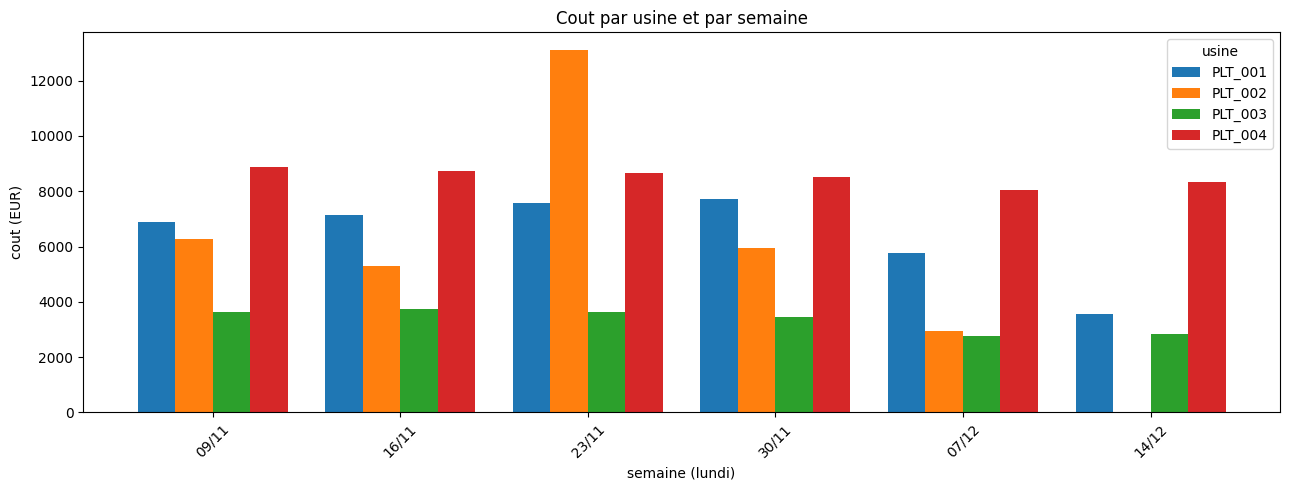

In [20]:
cout_usine_sem = envois.groupby([envois["semaine"].dt.date, "plant"])["cout"].sum().unstack(fill_value=0)
etiquettes = [d.strftime("%d/%m") for d in cout_usine_sem.index]
x = np.arange(len(cout_usine_sem)); n_u = cout_usine_sem.shape[1]; larg = 0.8 / n_u
fig, ax = plt.subplots(figsize=(13, 5))
for i, usine in enumerate(cout_usine_sem.columns):
    ax.bar(x + (i - (n_u - 1) / 2) * larg, cout_usine_sem[usine].values, width=larg, label=usine)
ax.set_title("Cout par usine et par semaine")
ax.set_xlabel("semaine (lundi)"); ax.set_ylabel("cout (EUR)")
ax.set_xticks(x); ax.set_xticklabels(etiquettes, rotation=45); ax.legend(title="usine")
plt.tight_layout()
plt.show()

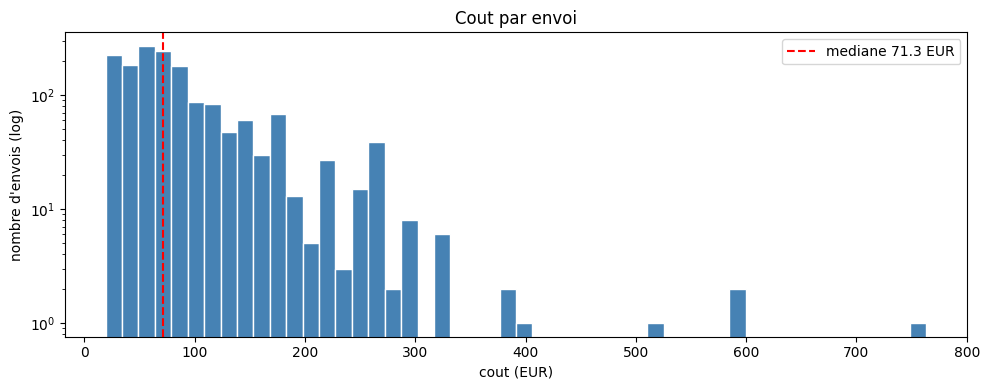

In [21]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(envois["cout"], bins=50, color="steelblue", edgecolor="white")
ax.axvline(envois["cout"].median(), color="red", linestyle="--",
           label="mediane " + str(round(envois["cout"].median(), 1)) + " EUR")
ax.set_yscale("log"); ax.set_title("Cout par envoi")
ax.set_xlabel("cout (EUR)"); ax.set_ylabel("nombre d'envois (log)"); ax.legend()
plt.tight_layout()
plt.show()

**Notre constat :** la situation actuelle coûte **143 422 €** sur l'horizon,
soit **23 904 € par semaine**. Un envoi coûte en moyenne **89,70 €** et nous payons
**88,81 €/tonne**. Comme chaque envoi part presque vide, nous payons surtout des
camions quasi vides.

### 5.2 Le coût des lignes inconnues, au pire cas (H16)

Chaque ligne inconnue occupe un camion plein, seule : son prix est celui de la
colonne `>4000` sur sa ligne de grille. C'est volontairement pessimiste, et ce
coût n'entre jamais dans nos économies.

In [22]:
lignes_inconnues["cout"] = [prix_camion_plein(l, grille_prix) for l in lignes_inconnues["ligne_grille"]]
cout_inconnues = lignes_inconnues["cout"].sum()
camions_inconnues = len(lignes_inconnues)
cout_moyen_camion_inconnu = cout_inconnues / camions_inconnues
print("Cout des lignes inconnues (pire cas H16) :", round(cout_inconnues, 2), "EUR")
print("Lignes inconnues                         :", len(lignes_inconnues))
print("Camions (un par ligne)                   :", camions_inconnues)
print("Cout moyen par camion                    :", round(cout_moyen_camion_inconnu, 2), "EUR")

Cout des lignes inconnues (pire cas H16) : 35032.42 EUR
Lignes inconnues                         : 138
Camions (un par ligne)                   : 138
Cout moyen par camion                    : 253.86 EUR


**Notre constat :** au pire cas, les **138** lignes inconnues coûtent **35 032 €**
sur la période : **138 camions** pleins, un par ligne, soit **253,86 €** par camion
en moyenne. La réalité ne peut être que meilleure : ces lignes sont livrées comme
aujourd'hui et ce chiffre n'entre jamais dans nos économies.

### 5.3 Le coût total de notre situation actuelle

Nous additionnons le coût du périmètre optimisé et le coût au pire cas des lignes
inconnues. C'est le coût maximal de notre situation actuelle.

Cout du perimetre optimise      : 143422.43 EUR
Cout des lignes inconnues (H16) : 35032.42 EUR
Cout total au plus              : 178454.85 EUR
Part estimee au pire cas        : 19.6 %


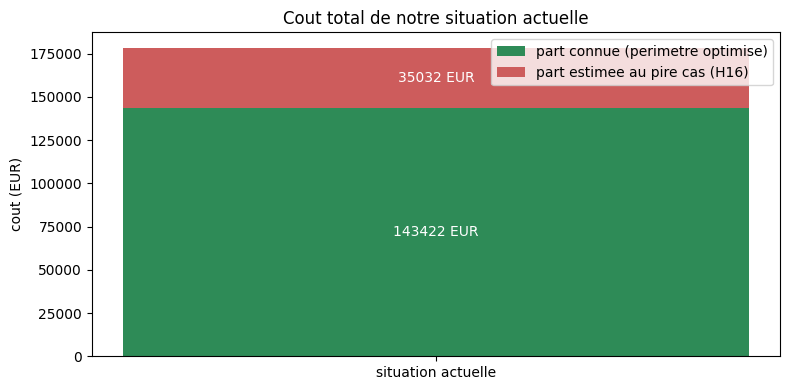

In [23]:
cout_complet = cout_total + cout_inconnues
part_estimee = cout_inconnues / cout_complet * 100
print("Cout du perimetre optimise      :", round(cout_total, 2), "EUR")
print("Cout des lignes inconnues (H16) :", round(cout_inconnues, 2), "EUR")
print("Cout total au plus              :", round(cout_complet, 2), "EUR")
print("Part estimee au pire cas        :", round(part_estimee, 1), "%")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(["situation actuelle"], [cout_total], color="seagreen",
       label="part connue (perimetre optimise)")
ax.bar(["situation actuelle"], [cout_inconnues], bottom=[cout_total], color="indianred",
       label="part estimee au pire cas (H16)")
ax.text(0, cout_total / 2, str(round(cout_total)) + " EUR", ha="center", va="center", color="white")
ax.text(0, cout_total + cout_inconnues / 2, str(round(cout_inconnues)) + " EUR",
        ha="center", va="center", color="white")
ax.set_title("Cout total de notre situation actuelle")
ax.set_ylabel("cout (EUR)")
ax.legend()
plt.tight_layout()
plt.show()

**Notre constat :** aujourd'hui, nos livraisons coûtent au plus **178 455 €** sur
la période, dont **35 032 € (19,6 %)** estimés au pire cas faute de données. La
part connue, celle que nous optimiserons, est de **143 422 €**.

## Section 6 : Notre baseline (indicateurs de référence)

Nous résumons notre situation actuelle sur deux colonnes : la **situation
complète** (périmètre + lignes inconnues au pire cas) et le **périmètre
optimisé** seul. Certains indicateurs n'ont de sens que sur le périmètre : nous
les laissons vides pour la situation complète.

In [24]:
remp_median = envois["remplissage_poids_%"].median()
remp_moyen = envois["remplissage_poids_%"].mean()
part_sous_10 = (envois["remplissage_poids_%"] < 10).mean() * 100
TIRET = ""

baseline = pd.DataFrame({
    "situation complete": [
        camions_complet,
        round(cout_complet, 2),
        round(cout_complet / NB_SEMAINES, 2),
        round(cout_complet / camions_complet, 2),
        TIRET, TIRET, TIRET, TIRET, TIRET, TIRET,
    ],
    "perimetre optimise": [
        nb_camions_total,
        round(cout_total, 2),
        round(cout_moyen_semaine, 2),
        round(cout_total / nb_camions_total, 2),
        round(nb_envois),
        round(nb_envois / NB_SEMAINES, 1),
        round(cout_par_tonne, 2),
        round(remp_median, 2),
        round(remp_moyen, 2),
        round(part_sous_10, 1),
    ],
}, index=[
    "Nombre de camions",
    "Cout total (EUR)",
    "Cout moyen par semaine (EUR)",
    "Cout par camion (EUR)",
    "Nombre d'envois",
    "Envois par semaine",
    "Cout par tonne (EUR/t)",
    "Remplissage median (%)",
    "Remplissage moyen (%)",
    "Part des camions sous 10 % (%)",
])
display(baseline)

,situation complete,perimetre optimise
Nombre de camions,1742,1604.00
Cout total (EUR),178454.85,143422.43
Cout moyen par semaine (EUR),29742.48,23903.74
Cout par camion (EUR),102.44,89.42
Nombre d'envois,,1599.00
Envois par semaine,,266.50
Cout par tonne (EUR/t),,88.81
Remplissage median (%),,1.32
Remplissage moyen (%),,3.92
Part des camions sous 10 % (%),,92.90


**Notre constat :** sur notre périmètre optimisé, notre baseline est de **1 599
envois**, **1 604 camions**, **143 422 €** sur l'horizon, un remplissage médian de
**1,3 %** et **92,9 %** de camions sous 10 %. La situation complète coûte au plus
**178 455 €** pour **1 742 camions**. Notre algorithme sera comparé à la colonne
**périmètre optimisé** : c'est là que nous mesurons nos économies.

## Section 7 : Les couples à fort potentiel

Pour classer les couples, nous faisons une estimation **volontairement simple** :
pour chaque couple et chaque semaine, nous regroupons tous les besoins sur **un
seul envoi daté du lundi** de la semaine. Cela respecte R1 (4 jours d'avance au
plus). Camions et coût sont calculés sur cet envoi du lundi avec notre estimateur
(H13), jamais sur un total abstrait.

Ce n'est **pas encore** notre optimisation (un seul profil, pas de lissage) : c'est
un ordre de grandeur pour classer les couples.

In [25]:
# Un couple sur une semaine : besoins actuels regroupes sur un seul envoi du lundi.
cs = envois.groupby(["supplier_id", "plant", "semaine"]).agg(
    poids=("poids", "sum"), volume=("volume", "sum"),
    ligne_grille=("ligne_grille", "first"), envois=("cout", "size"),
    cout_actuel=("cout", "sum")).reset_index()
cs["cout_regroupe"] = [cout_envoi(p, v, l, grille_prix)
                       for p, v, l in zip(cs["poids"], cs["volume"], cs["ligne_grille"])]

potentiel_couples = cs.groupby(["supplier_id", "plant"]).agg(
    envois=("envois", "sum"), poids=("poids", "sum"),
    cout_actuel=("cout_actuel", "sum"), cout_regroupe=("cout_regroupe", "sum")).reset_index()
potentiel_couples = potentiel_couples.merge(
    envois.groupby(["supplier_id", "plant"])["distance"].first().reset_index(), on=["supplier_id", "plant"])
potentiel_couples["envois_par_sem"] = potentiel_couples["envois"] / NB_SEMAINES
potentiel_couples["poids_moyen_envoi"] = potentiel_couples["poids"] / potentiel_couples["envois"]
potentiel_couples["remplissage_actuel_%"] = potentiel_couples["poids_moyen_envoi"] / CAP_POIDS * 100
potentiel_couples["gain_eur"] = potentiel_couples["cout_actuel"] - potentiel_couples["cout_regroupe"]
potentiel_couples["gain_%"] = np.where(potentiel_couples["cout_actuel"] > 0,
                                       potentiel_couples["gain_eur"] / potentiel_couples["cout_actuel"] * 100, 0)
potentiel_couples = potentiel_couples.sort_values("gain_eur", ascending=False).reset_index(drop=True)
colonnes = ["supplier_id", "plant", "distance", "envois_par_sem", "poids_moyen_envoi",
            "remplissage_actuel_%", "cout_actuel", "cout_regroupe", "gain_eur", "gain_%"]
potentiel_couples[colonnes].head(10).round(2)

,supplier_id,plant,distance,envois_par_sem,poids_moyen_envoi,remplissage_actuel_%,cout_actuel,cout_regroupe,gain_eur,gain_%
0,SUP_00085,PLT_004,121.0,5.00,2362.26,9.64,7429.18,1988.44,5440.74,73.23
1,SUP_00146,PLT_002,122.0,3.33,2616.18,10.68,4651.48,1472.49,3178.99,68.34
2,SUP_00059,PLT_003,122.0,4.17,929.35,3.79,3874.58,1859.00,2015.58,52.02
3,SUP_00144,PLT_001,38.0,3.33,3470.82,14.17,3240.69,1283.49,1957.20,60.39
4,SUP_00080,PLT_004,40.0,4.83,954.78,3.90,2989.46,1276.40,1713.06,57.30
5,SUP_00118,PLT_001,100.0,4.83,662.07,2.70,3210.51,1540.68,1669.83,52.01
6,SUP_00129,PLT_003,84.0,4.33,702.17,2.87,3041.89,1488.05,1553.84,51.08
7,SUP_00149,PLT_004,13.0,5.00,855.47,3.49,2516.99,963.75,1553.23,61.71
8,SUP_00087,PLT_004,98.0,4.67,589.14,2.40,2995.95,1446.40,1549.55,51.72
9,SUP_00011,PLT_004,145.0,5.00,303.82,1.24,2861.52,1320.68,1540.84,53.85


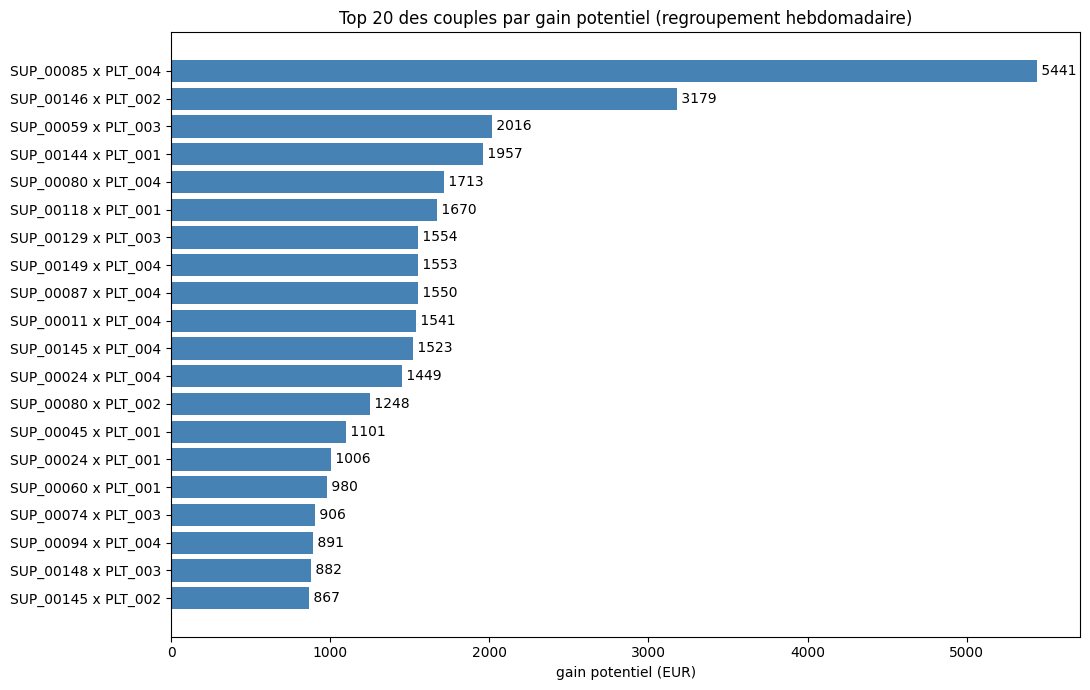

In [26]:
top20 = potentiel_couples.head(20)
etiquettes = top20["supplier_id"] + " x " + top20["plant"]
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(etiquettes, top20["gain_eur"], color="steelblue")
ax.invert_yaxis()
ax.set_title("Top 20 des couples par gain potentiel (regroupement hebdomadaire)")
ax.set_xlabel("gain potentiel (EUR)")
for i, v in enumerate(top20["gain_eur"]):
    ax.text(v, i, " " + str(round(v)), va="center")
plt.tight_layout()
plt.show()

In [27]:
gain_total = potentiel_couples["gain_eur"].sum()
part_top10 = potentiel_couples.head(10)["gain_eur"].sum() / gain_total * 100
part_top20 = potentiel_couples.head(20)["gain_eur"].sum() / gain_total * 100
print("Gain potentiel total :", round(gain_total, 2), "EUR")
print("Part portee par les 10 premiers couples :", round(part_top10, 1), "%")
print("Part portee par les 20 premiers couples :", round(part_top20, 1), "%")
print("Couples avec un gain positif :", int((potentiel_couples["gain_eur"] > 0).sum()),
      "sur", len(potentiel_couples))

Gain potentiel total : 55497.74 EUR
Part portee par les 10 premiers couples : 40.0 %
Part portee par les 20 premiers couples : 59.5 %
Couples avec un gain positif : 119 sur 171


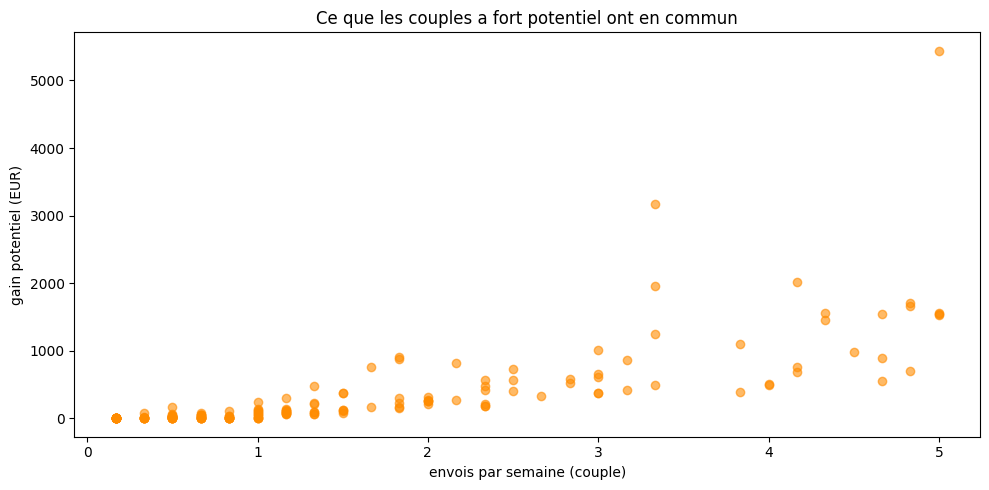

In [28]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(potentiel_couples["envois_par_sem"], potentiel_couples["gain_eur"],
           alpha=0.6, color="darkorange")
ax.set_title("Ce que les couples a fort potentiel ont en commun")
ax.set_xlabel("envois par semaine (couple)"); ax.set_ylabel("gain potentiel (EUR)")
plt.tight_layout()
plt.show()

**Notre constat :** le gain se concentre : les **20 premiers couples** portent
**59,5 %** du gain total (40 % pour les 10 premiers). Ce sont les couples qui
livrent souvent et peu rempli : plus un couple multiplie les envois par semaine,
plus son gain de regroupement est grand. **119 couples sur 171** ont un gain
positif.

## Section 8 : Notre objectif d'amélioration

Nous résumons le gain accessible et nous fixons notre objectif chiffré pour le
milestone 3.

In [29]:
envois_regroupes = len(cs)   # un envoi par couple et par semaine
envois_evitables = nb_envois - envois_regroupes
cout_regroupe_total = cs["cout_regroupe"].sum()
gain_pct = gain_total / cout_total * 100
objectif_min = 0.35 * cout_total
print("Cout actuel (perimetre optimise) :", round(cout_total, 2), "EUR")
print("Cout apres regroupement hebdo    :", round(cout_regroupe_total, 2), "EUR")
print("Gain potentiel                   :", round(gain_total, 2), "EUR  (", round(gain_pct, 1), "% )")
print("Envois actuels                   :", nb_envois)
print("Envois apres regroupement        :", envois_regroupes)
print("Envois evitables                 :", envois_evitables)
print("Objectif minimal (35 % du perimetre) :", round(objectif_min, 2), "EUR",
      " soit", round(objectif_min / cout_complet * 100, 1), "% du cout total complet")

Cout actuel (perimetre optimise) : 143422.43 EUR
Cout apres regroupement hebdo    : 87924.69 EUR
Gain potentiel                   : 55497.74 EUR  ( 38.7 % )
Envois actuels                   : 1599
Envois apres regroupement        : 706
Envois evitables                 : 893
Objectif minimal (35 % du perimetre) : 50197.85 EUR  soit 28.1 % du cout total complet


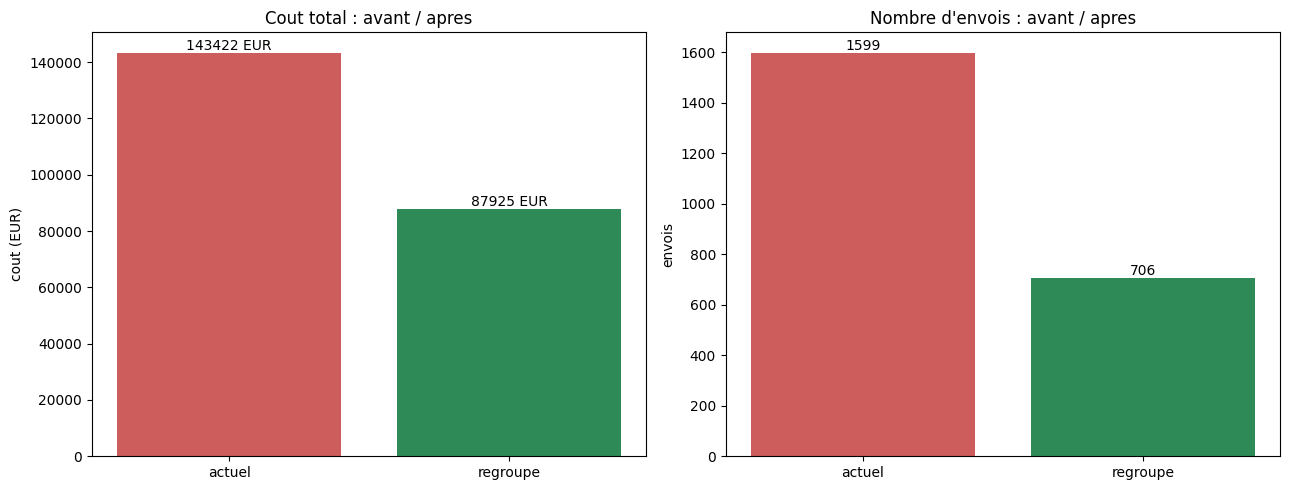

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
barres1 = ax1.bar(["actuel", "regroupe"], [cout_total, cout_regroupe_total], color=["indianred", "seagreen"])
ax1.set_title("Cout total : avant / apres"); ax1.set_ylabel("cout (EUR)")
for b, v in zip(barres1, [cout_total, cout_regroupe_total]):
    ax1.text(b.get_x() + b.get_width() / 2, v, str(round(v)) + " EUR", ha="center", va="bottom")
barres2 = ax2.bar(["actuel", "regroupe"], [nb_envois, envois_regroupes], color=["indianred", "seagreen"])
ax2.set_title("Nombre d'envois : avant / apres"); ax2.set_ylabel("envois")
for b, v in zip(barres2, [nb_envois, envois_regroupes]):
    ax2.text(b.get_x() + b.get_width() / 2, v, str(int(v)), ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Notre objectif pour le milestone 3 :** réduire d'**au moins 35 %** le coût de
transport de notre périmètre optimisé, **sans retard ni dépassement de capacité**.
Un simple regroupement hebdomadaire montre déjà **38,7 %** de gain (**55 498 €**,
**893 envois évités**) : c'est un ordre de grandeur atteignable, que notre
optimisation devra confirmer et dépasser.

Sur notre périmètre, nous visons **au moins 50 198 €** d'économies (35 % du coût du
périmètre), soit **28 %** du coût total de notre situation actuelle (**178 455 €**).
Les lignes inconnues restent livrées comme aujourd'hui.

Au milestone 3, nos **profils** seront des **paramètres** (1, 2, 3, 5 par semaine,
et d'autres si besoin), tout comme l'**avance maximale** (7 jours). Ainsi nous ne
restons pas bloqués sur une seule hypothèse et nous cherchons le meilleur
compromis coût / régularité.

## Section 9 : Notre bilan

Aujourd'hui, nous faisons **1 665 envois** pour un coût d'au plus **178 455 €**,
dont **35 032 €** estimés au pire cas faute de données. Nous optimisons les **97 %**
de lignes que nous connaissons ; sur ce périmètre, nous visons **au moins
50 198 €** d'économies. Nos chiffres sont un **minimum garanti**.

Ce que nous retenons de ce milestone :

- La situation complète coûte au plus **178 455 €** pour **1 742 camions** ; le
  périmètre optimisé en représente **143 422 €** et **1 604 camions**.
- Nos camions sont presque vides : remplissage médian **1,3 %**, et **92,9 %** des
  envois sous 10 %. Le gaspillage vient du **nombre d'envois**, pas de la capacité.
- Le **poids** est la limite qui décide du nombre de camions.
- Un regroupement hebdomadaire simple montre déjà **38,7 %** d'économie possible sur
  le périmètre, concentrée sur une minorité de couples.

**Nos limites :**

Deux choix jouent volontairement contre nous. Les envois mixtes sont comptés en
camions séparés (un pour la partie connue, un par ligne inconnue), soit plus de
camions qu'en réalité. Les lignes inconnues sont chiffrées au pire cas, un camion
plein chacune. Ces deux choix gonflent notre coût actuel, jamais nos économies :
nos gains sont donc sous-estimés, jamais exagérés.

In [31]:
# Nos exports pour la suite.
os.makedirs(DOSSIER_SORTIE, exist_ok=True)
envois.to_csv(DOSSIER_SORTIE + "envois_actuels.csv", index=False)
lignes_inconnues.to_csv(DOSSIER_SORTIE + "lignes_inconnues.csv", index=False)
baseline.to_csv(DOSSIER_SORTIE + "baseline.csv")
potentiel_couples.to_csv(DOSSIER_SORTIE + "potentiel_couples.csv", index=False)
print("Fichiers exportes dans", DOSSIER_SORTIE, ":")
print("  - envois_actuels.csv     (", len(envois), "envois )")
print("  - lignes_inconnues.csv   (", len(lignes_inconnues), "lignes )")
print("  - baseline.csv           (", len(baseline), "indicateurs, 2 colonnes )")
print("  - potentiel_couples.csv  (", len(potentiel_couples), "couples )")

Fichiers exportes dans ../data/processed/ :
  - envois_actuels.csv     ( 1599 envois )
  - lignes_inconnues.csv   ( 138 lignes )
  - baseline.csv           ( 10 indicateurs, 2 colonnes )
  - potentiel_couples.csv  ( 171 couples )
